# Experiment 7: Convergence of a Genetic Algorithm

**Aim:** To study the convergence of a Genetic Algorithm by observing changes in fitness values over multiple generations using Python.

**Theory:** Convergence means the population's fitness stops improving and settles near an optimum. Plotting best and average fitness against generation number shows how fast the GA converges. The mutation rate affects this: too low can stall, too high disrupts good solutions.

**Step 0:** Import the required libraries, fix the random seed and define the helper functions needed from earlier experiments.

In [1]:
import random, numpy as np
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42)

def bits_to_int(b): return int("".join(map(str,b)), 2)

def tournament(pop, fits, k, size=3):
    chosen = []
    for _ in range(k):
        idx = random.sample(range(len(pop)), size)
        chosen.append(pop[max(idx, key=lambda i: fits[i])])
    return chosen

def one_point(p1, p2):
    pt = random.randint(1, len(p1)-1)
    return p1[:pt]+p2[pt:], p2[:pt]+p1[pt:], pt

def bit_flip(ind, pm=0.2):
    return [1-g if random.random() < pm else g for g in ind]

# Simple GA from Experiment 6
N_BITS, POP_SIZE, GENS, PC, PM = 10, 30, 40, 0.8, 0.02
def fit(ind): return bits_to_int(ind)**2
def init_pop(): return [[random.randint(0,1) for _ in range(N_BITS)] for _ in range(POP_SIZE)]

def run_ga(verbose=True):
    pop = init_pop(); best_hist, avg_hist = [], []
    for g in range(GENS):
        fits = [fit(i) for i in pop]
        best_hist.append(max(fits)); avg_hist.append(sum(fits)/len(fits))
        new = [max(pop, key=fit)[:]]                       # elitism
        while len(new) < POP_SIZE:
            p1, p2 = tournament(pop, fits, 2)
            if random.random() < PC: c1, c2, _ = one_point(p1, p2)
            else: c1, c2 = p1[:], p2[:]
            new += [bit_flip(c1, PM), bit_flip(c2, PM)]
        pop = new[:POP_SIZE]
        if verbose and (g % 5 == 0 or g == GENS-1):
            print(f"Gen {g:>2}: best={best_hist[-1]:>8}  avg={avg_hist[-1]:>12.1f}")
    return max(pop, key=fit), best_hist, avg_hist

**Step 1:** Run the GA and record best and average fitness per generation.

In [2]:
best, bh, ah = run_ga(verbose=False)

**Step 2:** Plot the convergence curve.

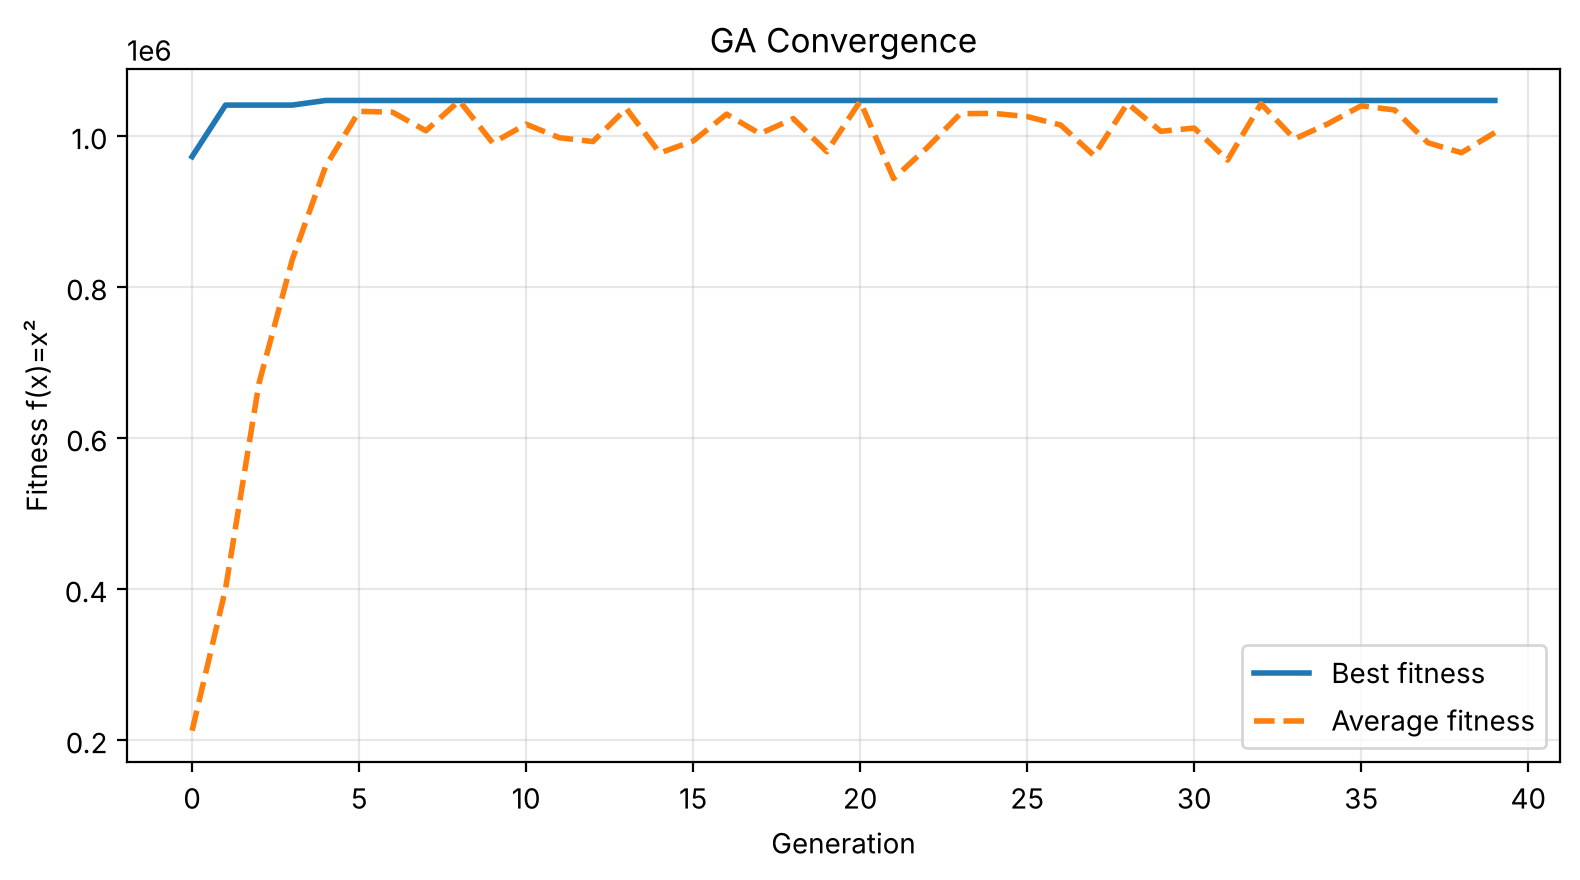

In [3]:
plt.figure(figsize=(8,4.5))
plt.plot(bh, label="Best fitness", lw=2)
plt.plot(ah, label="Average fitness", lw=2, linestyle="--")
plt.xlabel("Generation"); plt.ylabel("Fitness f(x)=x²")
plt.title("GA Convergence"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**Step 3:** Compare convergence for different mutation rates (average of 10 runs).

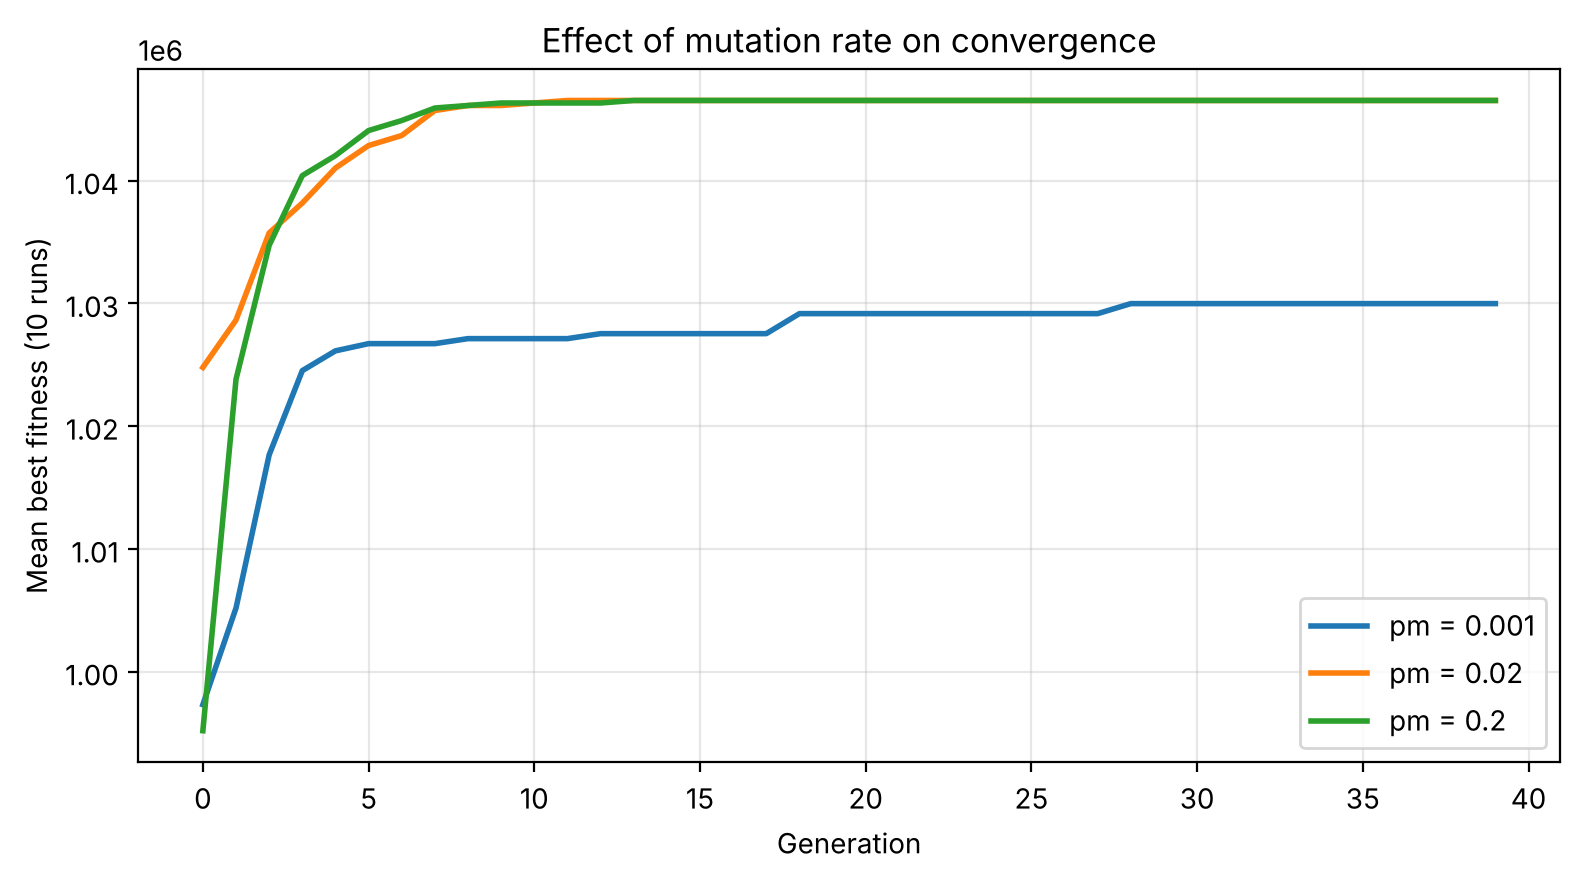

In [4]:
plt.figure(figsize=(8,4.5))
for pm in [0.001, 0.02, 0.2]:
    PM = pm
    runs = np.mean([run_ga(verbose=False)[1] for _ in range(10)], axis=0)
    plt.plot(runs, label=f"pm = {pm}", lw=2)
PM = 0.02
plt.xlabel("Generation"); plt.ylabel("Mean best fitness (10 runs)")
plt.title("Effect of mutation rate on convergence"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()